<a href="https://colab.research.google.com/github/GianAlbertCrist/gamedev/blob/main/ML_Healthcare_Dataset_DT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import gdown
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

file_id = "1ayvcOjwXtLMclrLlSv_jtEZ8xLam3xWW"  # Replace with your actual file ID
file_name = "healthcare_dataset.csv"  # Change this if needed

gdown.download(f"https://drive.google.com/uc?id={file_id}", file_name, quiet=False)

df = pd.read_csv("healthcare_dataset.csv")
print(df.head())

Downloading...
From: https://drive.google.com/uc?id=1ayvcOjwXtLMclrLlSv_jtEZ8xLam3xWW
To: /content/healthcare_dataset.csv
100%|██████████| 69.4k/69.4k [00:00<00:00, 82.3MB/s]

  patient_id   Age   BMI  BloodPressure Cholesterol  GlucoseLevel  HeartRate  \
0    pid7698  57.0  28.9           91.0        High          80.0       78.0   
1    pid8357  47.0  22.2          107.0      Normal          93.0       71.0   
2    pid3321  59.0  20.9          113.0      Normal          79.0       82.0   
3    pid4018  72.0  25.0          148.0      Normal         100.0       65.0   
4    pid8521  46.0  24.1          128.0      Normal          88.0       75.0   

  SmokingHistory ExerciseFrequency  HasDisease  
0          Never              High         0.0  
1          Never               NaN         0.0  
2          Never               NaN         0.0  
3          Never          Moderate         0.0  
4          Never               Low         1.0  


In [ ]:
# Check for missing values
print(df.isnull().sum())

patient_id             0
Age                   75
BMI                   74
BloodPressure         73
Cholesterol           75
GlucoseLevel          75
HeartRate             75
SmokingHistory        75
ExerciseFrequency    376
HasDisease            75
dtype: int64


In [ ]:
# Handling Missing Values
df.fillna(df.median(numeric_only=True), inplace=True)  # Fill numeric missing values with median
df.fillna(df.mode().iloc[0], inplace=True)  # Fill categorical missing values with mode

# Convert categorical features to numerical using Label Encoding
categorical_cols = df.select_dtypes(include=['object']).columns
for col in categorical_cols:
    encoder = LabelEncoder()
    df[col] = encoder.fit_transform(df[col])

# Check for missing values
print(df.isnull().sum())

patient_id           0
Age                  0
BMI                  0
BloodPressure        0
Cholesterol          0
GlucoseLevel         0
HeartRate            0
SmokingHistory       0
ExerciseFrequency    0
HasDisease           0
dtype: int64


In [ ]:
# Identify outliers using IQR method
def detect_outliers_iqr(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = data[(data < lower_bound) | (data > upper_bound)]
    return outliers


In [ ]:
# Identify outliers for each numerical column
numerical_cols = df.select_dtypes(include=np.number).columns
for col in numerical_cols:
    outliers = detect_outliers_iqr(df[col])
    print(f"Outliers in {col}:\n{outliers}\n")


Outliers in patient_id:
Series([], Name: patient_id, dtype: int64)

Outliers in Age:
9       149.0
74      149.0
87      149.0
118     149.0
160     149.0
176     149.0
179      90.0
209     107.0
223     149.0
263     149.0
304     149.0
306     149.0
441     149.0
523     149.0
544      12.0
552     149.0
621     149.0
646       9.0
668      10.0
755      89.0
816     149.0
868     149.0
874     149.0
883     149.0
885     149.0
943     149.0
974     149.0
1026    149.0
1061      7.0
1101      6.0
1159    149.0
1160     12.0
1208    149.0
1251    149.0
1346     11.0
1355    149.0
1388    149.0
1408    149.0
1453     89.0
1460    149.0
1491    149.0
Name: Age, dtype: float64

Outliers in BMI:
9       63.9873
39      10.6000
74      63.9873
87      63.9873
91      10.4000
115     41.0000
118     63.9873
149     37.9000
160     63.9873
176     63.9873
223     63.9873
250     11.5000
263     63.9873
304     63.9873
306     63.9873
426     12.3000
434     38.2000
441     63.9873
457     4

In [ ]:
# Handling Outliers using Z-score
from scipy.stats import zscore
z_scores = np.abs(zscore(df.select_dtypes(include=[np.number])))
df = df[(z_scores < 3).all(axis=1)]  # Remove rows with z-score > 3 (outliers)

In [ ]:
# Save the processed dataset to a new CSV file
df.to_csv("processed_healthcare_dataset.csv", index=False)

In [ ]:
url = "https://drive.google.com/file/d/1Q-MJv_ouGb8Gzb-3wO3U4vHkaAd9gJ8D/view?usp=sharing"

file_id = "1Q-MJv_ouGb8Gzb-3wO3U4vHkaAd9gJ8D"  # Replace with your actual file ID
file_name = "proc_hc_dataset.csv"  # Change this if needed

gdown.download(f"https://drive.google.com/uc?id={file_id}", file_name, quiet=False)

df_proc = pd.read_csv("proc_hc_dataset.csv")
print(df_proc.head())

Downloading...
From: https://drive.google.com/uc?id=1Q-MJv_ouGb8Gzb-3wO3U4vHkaAd9gJ8D
To: /content/proc_hc_dataset.csv
100%|██████████| 58.5k/58.5k [00:00<00:00, 45.0MB/s]

   patient_id   Age   BMI  BloodPressure  Cholesterol  GlucoseLevel  \
0        1167  57.0  28.9           91.0            0          80.0   
1        1264  47.0  22.2          107.0            2          93.0   
2         370  59.0  20.9          113.0            2          79.0   
3         498  72.0  25.0          148.0            2         100.0   
4        1286  46.0  24.1          128.0            2          88.0   

   HeartRate  SmokingHistory  ExerciseFrequency  HasDisease  
0       78.0               2                  0         0.0  
1       71.0               2                  1         0.0  
2       82.0               2                  1         0.0  
3       65.0               2                  2         0.0  
4       75.0               2                  1         1.0  


In [ ]:
# Splitting Features and Target
X = df_proc.drop(columns=["HasDisease", "patient_id"])  # Features
y = df_proc["HasDisease"]  # Target

In [ ]:
# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Standardizing the data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# Display the standardized training data
X_train

array([[ 6.12599019e-01, -2.94726976e-03,  3.36065542e-01, ...,
         4.06266761e-01, -4.60251691e-01, -1.60014249e+00],
       [-2.21875131e+00, -1.17822777e+00,  1.08397958e+00, ...,
         7.09322648e-01,  7.55826171e-01, -1.14756392e-01],
       [-1.58169749e+00, -7.42938693e-01, -3.43856313e-01, ...,
         2.19224455e-03, -4.60251691e-01, -1.14756392e-01],
       ...,
       [-2.78502138e+00, -6.55880878e-01, -3.89538563e-03, ...,
        -4.01882272e-01,  7.55826171e-01,  1.37062971e+00],
       [ 6.12599019e-01, -1.59175238e+00,  1.08397958e+00, ...,
         1.03210874e-01,  7.55826171e-01, -1.14756392e-01],
       [-8.73859904e-01, -1.11293440e+00, -1.39879757e-01, ...,
         2.12358345e+00, -4.60251691e-01, -1.60014249e+00]])

Accuracy: 0.6539792387543253
              precision    recall  f1-score   support

         0.0       0.66      0.98      0.79       193
         1.0       0.00      0.00      0.00        96

    accuracy                           0.65       289
   macro avg       0.33      0.49      0.40       289
weighted avg       0.44      0.65      0.53       289



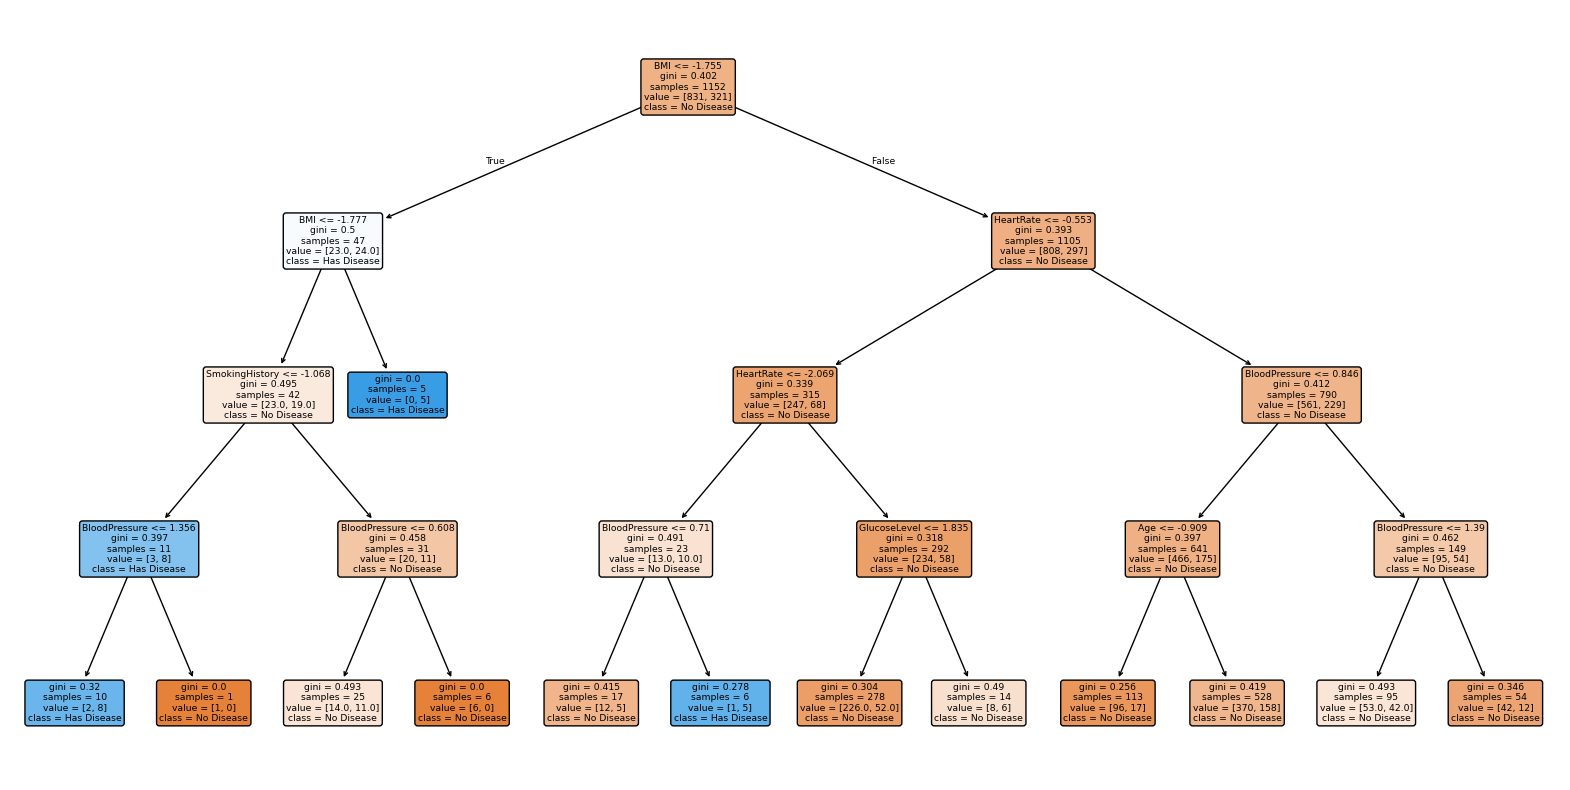

In [ ]:
# Initialize and train the Decision Tree Classifier
clf = DecisionTreeClassifier(max_depth=4, random_state=42)
clf.fit(X_train, y_train)

# Make predictions on the test set
y_pred = clf.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")
print(classification_report(y_test, y_pred))

# Plot the decision tree (optional, for visualization)
plt.figure(figsize=(20, 10))
plot_tree(clf, filled=True, feature_names=X.columns, class_names=["No Disease", "Has Disease"], rounded=True)
plt.show()

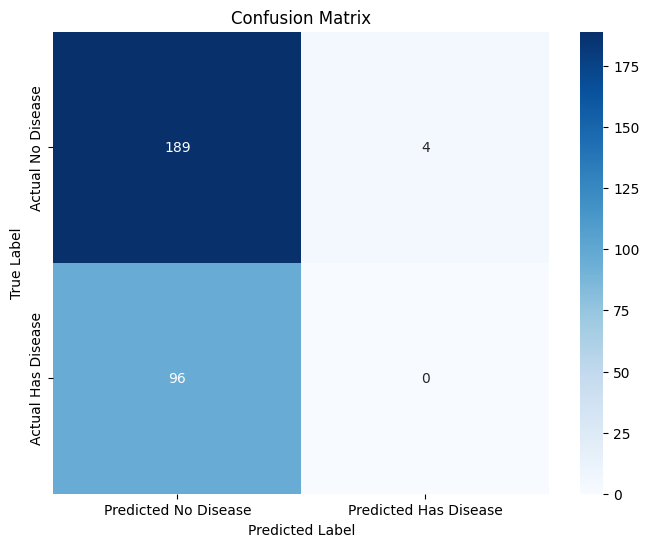

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted No Disease", "Predicted Has Disease"],
            yticklabels=["Actual No Disease", "Actual Has Disease"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()